# Alfido Tech — Task 3: Website Traffic Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

file_path = "traffic.csv"

try:
    df = pd.read_csv(file_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin1")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nUnique Values per Column:\n", df.nunique())
print("\nMissing Values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nExact Duplicates:", df.duplicated().sum())
df.head()

Shape: (226278, 9)

Columns: ['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

Data Types:
 event      str
date       str
country    str
city       str
artist     str
album      str
track      str
isrc       str
linkid     str
dtype: object

Unique Values per Column:
 event          3
date           7
country      211
city       11993
artist      2419
album       3254
track       3562
isrc         709
linkid      3839
dtype: int64

Missing Values:
 country      11
city         11
artist       37
album         5
track         5
isrc       7121
dtype: int64

Exact Duplicates: 103711


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


In [3]:
# 1. Inspect raw schema metrics before cleaning
print("Shape:", df.shape)
print("\nEvent Types:\n", df["event"].value_counts(dropna=False))
print("\nMissing Values Before Cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0])

# 2. Clean data (DO NOT drop duplicates — identical rows are distinct events on the same date)
df["date"] = pd.to_datetime(df["date"])
text_cols = ["event", "country", "city", "artist", "album", "track", "isrc", "linkid"]
for col in text_cols:
    df[col] = df[col].fillna("Unknown").astype(str).str.strip()

df["event"] = df["event"].str.lower()
df["DayOfWeek"] = df["date"].dt.day_name()

print("\nMissing Values After Cleaning:", df.isnull().sum().sum())

# 3. Core Funnel & Traffic Metrics
event_counts = df["event"].value_counts()
total_events = len(df)
pageviews = int(event_counts.get("pageview", 0))
previews = int(event_counts.get("preview", 0))
clicks = int(event_counts.get("click", 0))

unique_links = df["linkid"].nunique()
unique_countries = df[df["country"] != "Unknown"]["country"].nunique()
unique_cities = df[df["city"] != "Unknown"]["city"].nunique()
num_days = df["date"].nunique()

overall_ctr = (clicks / pageviews * 100) if pageviews > 0 else 0
preview_rate = (previews / pageviews * 100) if pageviews > 0 else 0
# Proxy Bounce / Non-Click Drop-off Rate: share of pageviews that did not convert to an outbound click
proxy_bounce_rate = max(0.0, min(100.0, 100.0 - overall_ctr)) if pageviews > 0 else 0

print("\n--- HEADLINE WEBSITE TRAFFIC KPIs ---")
print(f"Date Range: {df['date'].min().date()} to {df['date'].max().date()} ({num_days} days)")
print(f"Total Logged Events: {total_events:,}")
print(f"Pageviews (Session Volume): {pageviews:,}")
print(f"Previews (Mid-Funnel Engagement): {previews:,} ({preview_rate:.2f}% of pageviews)")
print(f"Outbound Clicks (Conversions): {clicks:,}")
print(f"Overall Click-Through Rate (CTR): {overall_ctr:.2f}%")
print(f"Proxy Bounce / Exit-Without-Click Rate: {proxy_bounce_rate:.2f}%")
print(f"Unique Landing Pages (linkid): {unique_links:,}")
print(f"Geographic Reach: {unique_countries:,} countries, {unique_cities:,} cities")
print("Note: Exact unique users, session duration, and HTTP referrers are unavailable at daily event-log granularity.")

# 4. Landing Page (linkid) Performance Table
link_events = df.pivot_table(index="linkid", columns="event", values="date", aggfunc="count", fill_value=0)
for col in ["pageview", "preview", "click"]:
    if col not in link_events.columns:
        link_events[col] = 0

link_meta = df.groupby("linkid")[["artist", "track"]].first()
link_perf = link_meta.join(link_events)
link_perf["Total_Events"] = link_perf[["pageview", "preview", "click"]].sum(axis=1)
link_perf["CTR_Pct"] = np.where(link_perf["pageview"] > 0, (link_perf["click"] / link_perf["pageview"]) * 100, 0)
link_perf["Dropoff_Rate_Pct"] = np.clip(100 - link_perf["CTR_Pct"], 0, 100)
link_perf = link_perf.sort_values("pageview", ascending=False)

# 5. Country Performance Table
country_events = df.pivot_table(index="country", columns="event", values="date", aggfunc="count", fill_value=0)
for col in ["pageview", "preview", "click"]:
    if col not in country_events.columns:
        country_events[col] = 0
country_events["Total_Events"] = country_events[["pageview", "preview", "click"]].sum(axis=1)
country_events["CTR_Pct"] = np.where(country_events["pageview"] > 0, (country_events["click"] / country_events["pageview"]) * 100, 0)
country_events["Dropoff_Rate_Pct"] = np.clip(100 - country_events["CTR_Pct"], 0, 100)
country_events = country_events.sort_values("pageview", ascending=False)

print("\n=== TOP 10 LANDING PAGES (BY PAGEVIEWS) ===")
print(link_perf[["artist", "track", "pageview", "preview", "click", "CTR_Pct", "Dropoff_Rate_Pct"]].head(10).round(2))

print("\n=== TOP 10 COUNTRIES (BY PAGEVIEWS) ===")
print(country_events[["pageview", "preview", "click", "CTR_Pct", "Dropoff_Rate_Pct"]].head(10).round(2))

Shape: (226278, 9)

Event Types:
 event
pageview    142015
click        55732
preview      28531
Name: count, dtype: int64

Missing Values Before Cleaning:
 country      11
city         11
artist       37
album         5
track         5
isrc       7121
dtype: int64

Missing Values After Cleaning: 0

--- HEADLINE WEBSITE TRAFFIC KPIs ---
Date Range: 2021-08-19 to 2021-08-25 (7 days)
Total Logged Events: 226,278
Pageviews (Session Volume): 142,015
Previews (Mid-Funnel Engagement): 28,531 (20.09% of pageviews)
Outbound Clicks (Conversions): 55,732
Overall Click-Through Rate (CTR): 39.24%
Proxy Bounce / Exit-Without-Click Rate: 60.76%
Unique Landing Pages (linkid): 3,839
Geographic Reach: 211 countries, 11,992 cities
Note: Exact unique users, session duration, and HTTP referrers are unavailable at daily event-log granularity.

=== TOP 10 LANDING PAGES (BY PAGEVIEWS) ===
                                                                                 artist  \
linkid                        

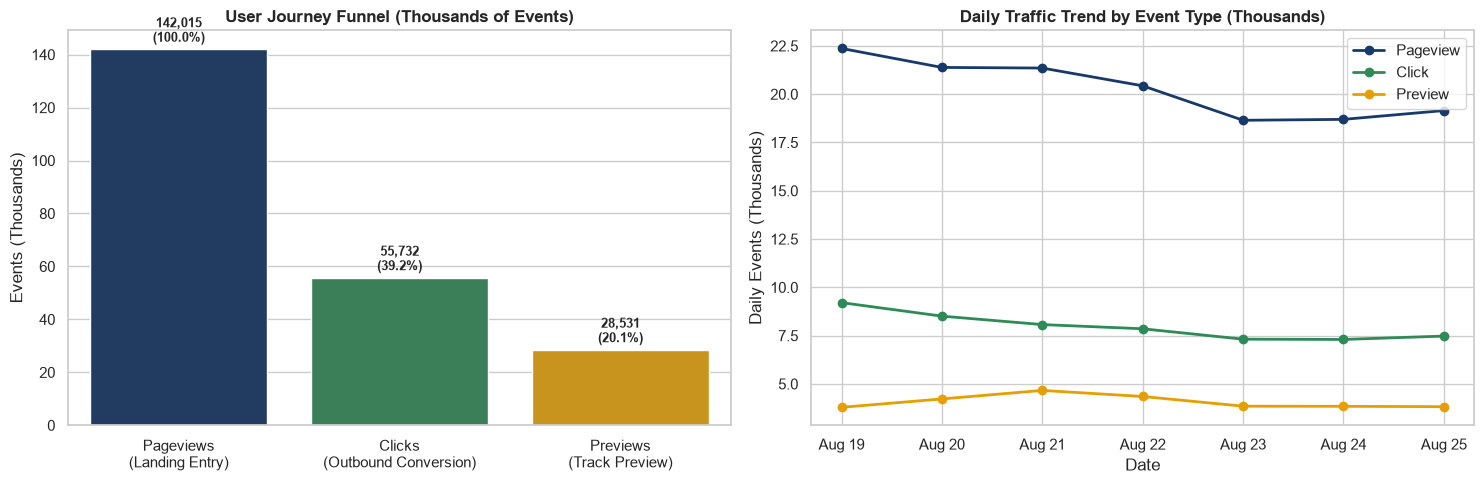

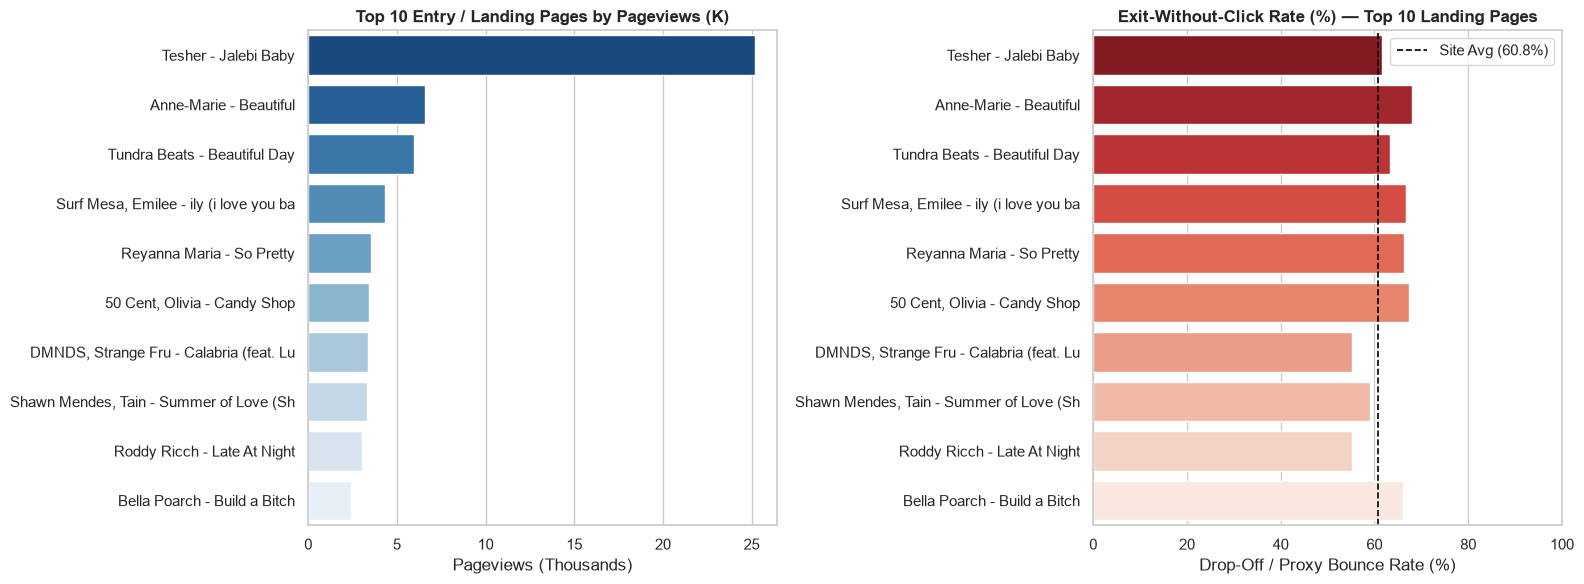

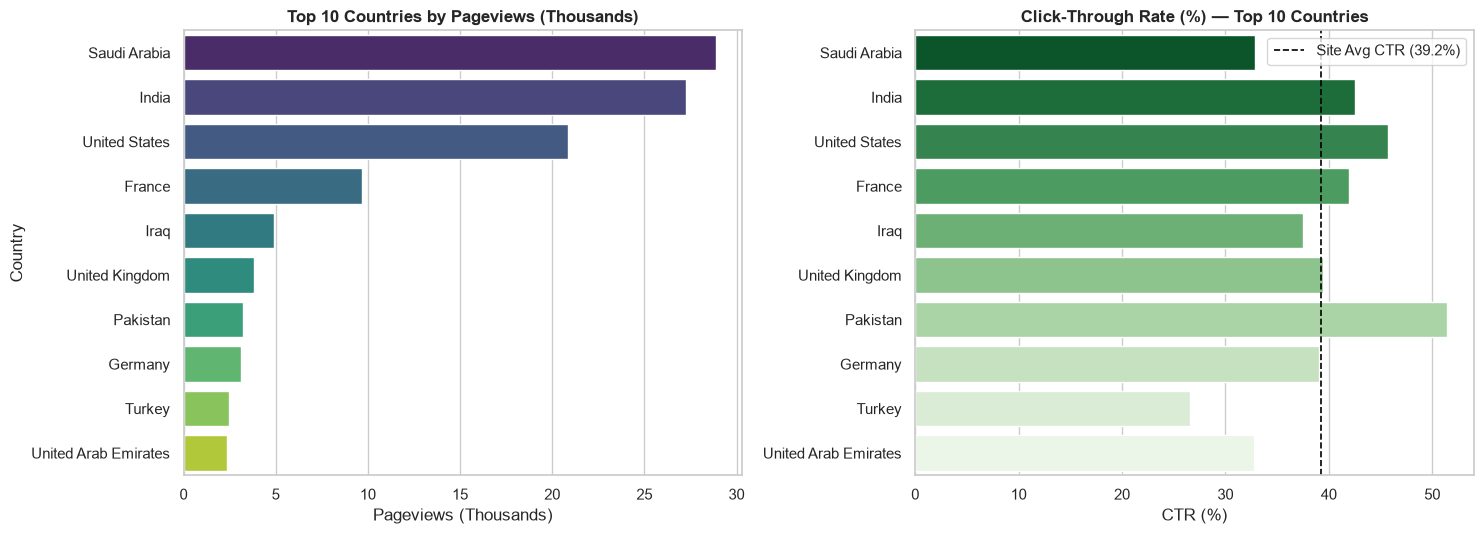

In [4]:
# --- CHART 1: User Engagement Funnel & Daily Traffic Trend ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

funnel_stages = ["Pageviews\n(Landing Entry)", "Clicks\n(Outbound Conversion)", "Previews\n(Track Preview)"]
funnel_vals = [pageviews, clicks, previews]
sns.barplot(x=funnel_stages, y=[v / 1e3 for v in funnel_vals], ax=axes[0], hue=funnel_stages, palette=["#183A6B", "#2E8B57", "#E69F00"], legend=False)
axes[0].set_title("User Journey Funnel (Thousands of Events)", fontweight="bold")
axes[0].set_ylabel("Events (Thousands)")
for i, v in enumerate(funnel_vals):
    pct = (v / pageviews * 100) if pageviews > 0 else 0
    axes[0].text(i, v / 1e3 + (max(funnel_vals) / 1e3 * 0.02), f"{v:,}\n({pct:.1f}%)", ha="center", fontsize=9, fontweight="bold")

daily_events = df.groupby(["date", "event"]).size().unstack(fill_value=0)
for col, color in [("pageview", "#183A6B"), ("click", "#2E8B57"), ("preview", "#E69F00")]:
    if col in daily_events.columns:
        axes[1].plot(daily_events.index.strftime("%b %d"), daily_events[col] / 1e3, marker="o", linewidth=2, label=col.capitalize(), color=color)
axes[1].set_title("Daily Traffic Trend by Event Type (Thousands)", fontweight="bold")
axes[1].set_ylabel("Daily Events (Thousands)")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.savefig("chart_traffic_funnel_trend.png", dpi=300)
plt.show()

# --- CHART 2: Top 10 Landing Pages (Volume vs. Proxy Bounce / Drop-Off Rate) ---
top10_links = link_perf.head(10).copy()
top10_links["Label"] = (top10_links["artist"].str[:18] + " - " + top10_links["track"].str[:18])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(y=top10_links["Label"], x=top10_links["pageview"] / 1e3, ax=axes[0], hue=top10_links["Label"], palette="Blues_r", legend=False)
axes[0].set_title("Top 10 Entry / Landing Pages by Pageviews (K)", fontweight="bold")
axes[0].set_xlabel("Pageviews (Thousands)")
axes[0].set_ylabel("")

sns.barplot(y=top10_links["Label"], x=top10_links["Dropoff_Rate_Pct"], ax=axes[1], hue=top10_links["Label"], palette="Reds_r", legend=False)
axes[1].axvline(proxy_bounce_rate, color="black", linestyle="--", linewidth=1.2, label=f"Site Avg ({proxy_bounce_rate:.1f}%)")
axes[1].set_title("Exit-Without-Click Rate (%) — Top 10 Landing Pages", fontweight="bold")
axes[1].set_xlabel("Drop-Off / Proxy Bounce Rate (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)
axes[1].legend()

plt.tight_layout()
plt.savefig("chart_top_landing_pages.png", dpi=300)
plt.show()

# --- CHART 3: Geographic Traffic Sources (Top 10 Countries & CTR) ---
top10_countries = country_events.head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(y=top10_countries.index, x=top10_countries["pageview"] / 1e3, ax=axes[0], hue=top10_countries.index, palette="viridis", legend=False)
axes[0].set_title("Top 10 Countries by Pageviews (Thousands)", fontweight="bold")
axes[0].set_xlabel("Pageviews (Thousands)")
axes[0].set_ylabel("Country")

sns.barplot(y=top10_countries.index, x=top10_countries["CTR_Pct"], ax=axes[1], hue=top10_countries.index, palette="Greens_r", legend=False)
axes[1].axvline(overall_ctr, color="black", linestyle="--", linewidth=1.2, label=f"Site Avg CTR ({overall_ctr:.1f}%)")
axes[1].set_title("Click-Through Rate (%) — Top 10 Countries", fontweight="bold")
axes[1].set_xlabel("CTR (%)")
axes[1].set_ylabel("")
axes[1].legend()

plt.tight_layout()
plt.savefig("chart_geo_distribution.png", dpi=300)
plt.show()

In [5]:
from fpdf import FPDF

def safe_text(val):
    """Sanitize international artist/track names for core Latin-1 PDF fonts."""
    return str(val).encode("latin-1", "replace").decode("latin-1")

class TrafficReport(FPDF):
    def header(self):
        if self.page_no() > 1:
            self.set_font("Helvetica", "I", 8)
            self.set_text_color(110, 110, 110)
            self.cell(0, 8, "Alfido Tech | Task 3: Website Traffic Analysis Report", align="R", new_x="LMARGIN", new_y="NEXT")
            self.ln(2)

    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(120, 120, 120)
        self.cell(0, 10, f"Page {self.page_no()}", align="C")

    def section_title(self, title):
        self.set_font("Helvetica", "B", 13)
        self.set_text_color(24, 58, 107)
        self.cell(0, 9, title, new_x="LMARGIN", new_y="NEXT")
        self.set_draw_color(24, 58, 107)
        self.line(15, self.get_y(), 195, self.get_y())
        self.ln(4)

    def body_text(self, text):
        self.set_font("Helvetica", "", 10)
        self.set_text_color(40, 40, 40)
        self.multi_cell(0, 5.5, safe_text(text))
        self.ln(2)

# GitHub repository folder link for Task 3
github_url = "https://github.com/ninaweaniket6-design/Alfido-Tech-Data-Analytics-Internship/tree/main/Task3_Website_Traffic"

# Pull exact live metrics from Cells 2 & 3
start_date = df["date"].min().strftime("%b %d, %Y")
end_date = df["date"].max().strftime("%b %d, %Y")
avg_daily_pv = pageviews / num_days

daily_pv = df[df["event"] == "pageview"].groupby("date").size()
peak_day = daily_pv.idxmax().strftime("%b %d")
peak_day_pv = int(daily_pv.max())
low_day = daily_pv.idxmin().strftime("%b %d")
low_day_pv = int(daily_pv.min())

top_link = link_perf.iloc[0]
top_link_name = safe_text(f"{top_link['artist']} - {top_link['track']}")
top_link_pv = int(top_link["pageview"])
top_link_share = (top_link_pv / pageviews) * 100

top10_c = country_events.head(10)
top_ctry = top10_c.index[0]
top_ctry_pv = int(top10_c.iloc[0]["pageview"])
top_ctry_ctr = top10_c.iloc[0]["CTR_Pct"]
top3_ctry_share = (country_events.iloc[:3]["pageview"].sum() / pageviews) * 100

best_ctr_ctry = top10_c["CTR_Pct"].idxmax()
best_ctr_val = top10_c.loc[best_ctr_ctry, "CTR_Pct"]
low_ctr_ctry = top10_c["CTR_Pct"].idxmin()
low_ctr_val = top10_c.loc[low_ctr_ctry, "CTR_Pct"]

high_drop_links = link_perf.head(10).sort_values("Dropoff_Rate_Pct", ascending=False)
worst_top_link = safe_text(f"{high_drop_links.iloc[0]['artist']} - {high_drop_links.iloc[0]['track']}")
worst_top_drop = high_drop_links.iloc[0]["Dropoff_Rate_Pct"]

pdf = TrafficReport()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.set_margins(15, 15, 15)

# ================= PAGE 1: TITLE, CODE LINK, EXEC SUMMARY & CLEANING =================
pdf.add_page()
pdf.set_fill_color(24, 58, 107)
pdf.rect(0, 0, 210, 42, "F")
pdf.set_y(10)
pdf.set_font("Helvetica", "B", 20)
pdf.set_text_color(255, 255, 255)
pdf.cell(0, 10, "Website Traffic Analysis Report", align="L", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "", 11)
pdf.cell(0, 7, "Alfido Tech Data Analytics Internship - Task 3 | Prepared by Aniket Ninawe", align="L", new_x="LMARGIN", new_y="NEXT")

# Clickable GitHub Link
pdf.set_y(47)
pdf.set_font("Helvetica", "B", 9.5)
pdf.set_text_color(40, 40, 40)
pdf.cell(0, 5.5, "GitHub Code & Notebook Repository:", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "U", 8.5)
pdf.set_text_color(17, 85, 204)
pdf.cell(0, 5.5, github_url, link=github_url, new_x="LMARGIN", new_y="NEXT")
pdf.ln(4)

pdf.section_title("1. Executive Summary & Headline Traffic KPIs")
pdf.body_text(
    f"This report analyzes {total_events:,} website traffic log events across {unique_links:,} unique landing pages "
    f"and {unique_countries:,} countries from {start_date} to {end_date} ({num_days} days) to evaluate user journeys, "
    f"landing-page engagement, exit drop-offs, and geographic traffic performance for Alfido Tech. Across {pageviews:,} "
    f"pageviews (averaging {avg_daily_pv:,.0f}/day), visitors generated {clicks:,} outbound clicks ({overall_ctr:.2f}% CTR) "
    f"and {previews:,} track previews ({preview_rate:.2f}%), leaving a {proxy_bounce_rate:.2f}% exit-without-click rate."
)

# KPI Grid
pdf.set_fill_color(235, 241, 249)
kpis = [
    ("Total Logged Events", f"{total_events:,}", "Pageviews (Sessions)", f"{pageviews:,}"),
    ("Outbound Clicks", f"{clicks:,}", "Track Previews", f"{previews:,} ({preview_rate:.1f}%)"),
    ("Overall CTR", f"{overall_ctr:.2f}%", "Proxy Bounce / Drop-Off", f"{proxy_bounce_rate:.2f}%"),
    ("Unique Landing Pages", f"{unique_links:,}", "Geographic Reach", f"{unique_countries:,} countries")
]
for k1, v1, k2, v2 in kpis:
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(45, 8, k1, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v1, border=1)
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(45, 8, k2, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v2, border=1, new_x="LMARGIN", new_y="NEXT")
pdf.ln(5)

pdf.section_title("2. Log Parsing, Data Cleaning & Schema Scope")
pdf.body_text(
    "- Event Integrity Preserved: Because the raw event log captures daily interactions without user-level IDs or second-level timestamps, identical rows represent distinct visitor events from the same city and day. Dropping exact duplicates was intentionally avoided to preserve true traffic counts.\n"
    "- Missing & Text Standardization: Parsed 'date' into datetime objects, normalized event names to lowercase, trimmed whitespace, and standardized missing geographic/metadata entries as 'Unknown' (0 nulls remaining).\n"
    "- Metric Adaptation: Because individual user IDs, session timestamps, and HTTP referrers are absent from this dataset schema, pageviews serve as session volume, outbound click-through rate (CTR) measures conversion efficiency, and non-click exit rate (100% - CTR) serves as the proxy bounce metric."
)

# ================= PAGE 2: USER FUNNEL, DAILY TREND & GEOGRAPHY =================
pdf.add_page()
pdf.section_title("3. User Journey Funnel & Daily Traffic Trends")
pdf.body_text(
    f"Visitor activity peaked on {peak_day} ({peak_day_pv:,} pageviews) before tapering to {low_day_pv:,} pageviews on "
    f"{low_day}. While {overall_ctr:.1f}% of landing visits click through to outbound destinations, only {preview_rate:.1f}% "
    f"engage with on-page previews, indicating an opportunity to improve interactive engagement before users exit."
)
pdf.image("chart_traffic_funnel_trend.png", w=180)
pdf.ln(3)

pdf.section_title("4. Geographic Traffic Sources & Conversion Efficiency")
pdf.body_text(
    f"Traffic is highly concentrated: the top 3 countries ({country_events.index[0]}, {country_events.index[1]}, and "
    f"{country_events.index[2]}) generate {top3_ctry_share:.1f}% of all pageviews. Notably, the #1 market ({top_ctry}, "
    f"{top_ctry_pv:,} pageviews) converts below average at {top_ctry_ctr:.1f}% CTR, while {best_ctr_ctry} achieves "
    f"{best_ctr_val:.1f}% CTR and {low_ctr_ctry} lags at {low_ctr_val:.1f}% CTR."
)
pdf.image("chart_geo_distribution.png", w=180)

# ================= PAGE 3: TOP LANDING PAGES & EXIT DROP-OFF =================
pdf.add_page()
pdf.section_title("5. Top Entry / Landing Pages & Exit-Without-Click Analysis")
pdf.body_text(
    f"Landing-page demand follows a steep power law: '{top_link_name}' alone captures {top_link_pv:,} pageviews "
    f"({top_link_share:.1f}% of total site traffic). Among the top 10 landing pages, '{worst_top_link}' exhibits the "
    f"highest exit-without-click rate at {worst_top_drop:.1f}%, highlighting high-impact targets for landing-page optimization."
)

# Top 8 Landing Pages Table
cols = ["Landing Page (Artist - Track)", "Pageviews", "Previews", "Clicks", "CTR %", "Drop-Off"]
widths = [72, 24, 22, 22, 20, 20]
pdf.set_font("Helvetica", "B", 8.5)
pdf.set_fill_color(24, 58, 107)
pdf.set_text_color(255, 255, 255)
for col, w in zip(cols, widths):
    pdf.cell(w, 8, col, border=1, align="C", fill=True)
pdf.ln()

pdf.set_font("Helvetica", "", 8.5)
pdf.set_text_color(30, 30, 30)
for idx, (_, row) in enumerate(link_perf.head(8).iterrows()):
    fill = idx % 2 == 1
    pdf.set_fill_color(245, 248, 252)
    label = safe_text(f"{row['artist']} - {row['track']}")
    if len(label) > 36:
        label = label[:33] + "..."
    vals = [
        label,
        f"{int(row['pageview']):,}",
        f"{int(row['preview']):,}",
        f"{int(row['click']):,}",
        f"{row['CTR_Pct']:.1f}%",
        f"{row['Dropoff_Rate_Pct']:.1f}%"
    ]
    for i, (val, w) in enumerate(zip(vals, widths)):
        align = "L" if i == 0 else "R"
        pdf.cell(w, 7, val, border=1, align=align, fill=fill)
    pdf.ln()

pdf.ln(5)
pdf.image("chart_top_landing_pages.png", w=180)
pdf.ln(1)
pdf.set_font("Helvetica", "I", 8.5)
pdf.set_text_color(90, 90, 90)
pdf.cell(0, 5, "Figure 3: Top 10 entry landing pages ranked by traffic volume alongside their exit-without-click rates.", align="C", new_x="LMARGIN", new_y="NEXT")

# ================= PAGE 4: 5 CONVERSION OPTIMIZATIONS =================
pdf.add_page()
pdf.section_title("6. Five Conversion Optimizations for Alfido Tech")
pdf.body_text("To lift outbound click-through rates, curb the 60.8% non-click exit rate, and improve attribution visibility, Alfido Tech should execute five targeted optimizations:")

recs = [
    (
        f"1. Localize Landing Pages & Outbound Destinations for {top_ctry}, {low_ctr_ctry} & UAE",
        f"{top_ctry} is the #1 traffic market ({top_ctry_pv:,} pageviews) yet converts at just {top_ctry_ctr:.1f}% CTR "
        f"(well below the {overall_ctr:.1f}% site average), with {low_ctr_ctry} ({low_ctr_val:.1f}%) and UAE also trailing. "
        f"Add localized Arabic/Turkish UI copy, prioritize region-preferred platforms at the top of the link list, and audit "
        f"mobile load latency across MENA networks to immediately unlock high-volume conversions."
    ),
    (
        f"2. Redesign High-Traffic, High-Drop-Off Entry Pages (Starting with '{worst_top_link}')",
        f"Several top-10 landing pages lose over 65% of visitors without a click. Run A/B tests placing a single primary "
        f"Call-to-Action (CTA) button above the fold, reducing visual clutter, and surfacing social proof to lift CTR on "
        f"the top 10 links that drive the majority of traffic."
    ),
    (
        "3. Turn Track Previews into a Guided Conversion Step",
        f"Only {preview_rate:.1f}% of pageviews trigger a preview. Embed an auto-ready, fast-loading preview widget directly "
        f"above the outbound CTA buttons and display a sticky 'Continue / Open Now' prompt right after preview playback to "
        f"convert passive browsers into active clickers."
    ),
    (
        f"4. Diversify Acquisition Beyond Single-Hit Dependency ('{top_link_name}')",
        f"With '{top_link_name}' generating {top_link_share:.1f}% of all pageviews and weekly traffic sliding from "
        f"{peak_day_pv:,} ({peak_day}) to {low_day_pv:,} ({low_day}), site volume is vulnerable to viral decay. Add "
        f"'Related / Trending Next' cross-links at the bottom of top landing pages to recycle exiting visitors into a "
        f"second pageview instead of letting them bounce."
    ),
    (
        "5. Upgrade Web Analytics Instrumentation for Full-Funnel Attribution",
        "Current logs lack anonymous session IDs, millisecond timestamps, and UTM/referrer tags, preventing exact bounce-rate, "
        "session-duration, and channel-ROI measurement. Implement lightweight first-party session IDs, UTM parameter capture, "
        "and scroll/exit telemetry so Alfido Tech can tie every conversion back to its exact referral source."
    )
]

for title, desc in recs:
    pdf.set_font("Helvetica", "B", 10.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(0, 7, safe_text(title), new_x="LMARGIN", new_y="NEXT")
    pdf.set_font("Helvetica", "", 10)
    pdf.set_text_color(40, 40, 40)
    pdf.multi_cell(0, 5.5, safe_text(desc))
    pdf.ln(3)

output_pdf = "Alfido_Tech_Task3_Website_Traffic_Report.pdf"
pdf.output(output_pdf)
print(f"PDF Report successfully generated: {output_pdf}")

PDF Report successfully generated: Alfido_Tech_Task3_Website_Traffic_Report.pdf
